In [21]:
import os
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"
os.environ["XLA_PYTHON_CLIENT_PREALLOCATE"] = "false"
import numpy as np
import jax
import jax.numpy as jnp
import torch
from feature_functions import dino_feature_extractor
from model_utils import (toggle_prompt_embedding_shape,
                         expand_prompt_embedding,
    fitness_function,
    generate_images_from_latents,
    get_text_embeddings,
    plot_thumbnails
)
from diffusers import (
    UNet2DConditionModel,
    AutoencoderKL,
    LMSDiscreteScheduler
)
from qdax.core.containers.dns_repertoire import DNSRepertoire
from qdax.core.containers.mapelites_repertoire import compute_cvt_centroids, MapElitesRepertoire
from qdax.core.emitters.mutation_operators import isoline_variation
from qdax.core.emitters.standard_emitters import MixingEmitter
from qdax.core.map_elites import MAPElites

from transformers import (
    AutoImageProcessor,
    AutoModel,
    CLIPTextModel,
    CLIPTokenizerFast,
    CLIPModel
)
from matplotlib import pyplot as plt
%matplotlib inline
from PIL import Image
from functools import partial
from typing import Optional, Union, List, Callable

## Hyperparameters

In [30]:
# Hyperparams
random_seed = 14643
key = jax.random.PRNGKey(random_seed)
model_name = "stabilityai/stable-diffusion-2-1"
batch_size = 4

num_inference_steps = 50
guidance_scale = 7.5

## Load the Models

In [3]:
vae = AutoencoderKL.from_pretrained(model_name, subfolder="vae", torch_dtype=torch.float32, cache_dir="/var/tmp/hf").cuda()
tokenizer = CLIPTokenizerFast.from_pretrained(model_name, subfolder="tokenizer", torch_dtype=torch.float32, cache_dir="/var/tmp/hf")
text_encoder = CLIPTextModel.from_pretrained(model_name, subfolder="text_encoder", torch_dtype=torch.float32, cache_dir="/var/tmp/hf").cuda().eval()
unet = UNet2DConditionModel.from_pretrained(model_name, subfolder="unet", torch_dtype=torch.float32, cache_dir="/var/tmp/hf").cuda()
unet.enable_gradient_checkpointing()
scheduler = LMSDiscreteScheduler.from_pretrained(model_name, subfolder="scheduler", torch_dtype=torch.float32, cache_dir="/var/tmp/hf")
clip_model = CLIPModel.from_pretrained("openai/clip-vit-base-patch32", cache_dir="/var/tmp/hf").to("cuda") # type: ignore

## Create Repertoire

In [4]:
key, subkey = jax.random.split(key)

init_latent = jax.random.normal(subkey, shape=(1, 4, 64, 64), dtype=jnp.float32)
init_prompt_embedding = get_text_embeddings(
    prompt=prompt,
    batch_size=1,  # type: ignore
    tokenizer=tokenizer,
    text_encoder=text_encoder,
    with_grad=False,  # No gradients needed for initial image generation
)


init_image = generate_images_from_latents(
    init_latent,
    init_prompt_embedding,
    num_inference_steps=num_inference_steps,
    guidance_scale=guidance_scale,
    scheduler=scheduler,
    unet=unet,
    vae=vae,
).squeeze()

init_prompt_embedding_jnp = jnp.array(init_prompt_embedding.detach().cpu().numpy(), dtype=jnp.float32)

## Utils

In [5]:
def show_image(image):
    image_array = np.array(image.cpu())
    image_array = (image_array - image_array.min()) / (image_array.max() - image_array.min() + 1e-8)
    image_array = (image_array * 255).astype(np.uint8)
    image_array = np.transpose(image_array, (1, 2, 0))
    image_plot = Image.fromarray(image_array, mode="RGB")

    # Show with corrected aspect ratio
    plt.figure(figsize=(10, 2))  # Adjust figsize to better match the image shape
    plt.imshow(image_plot)
    plt.axis('off')  # Optional: hides axis for better viewing
    plt.tight_layout()
    plt.show()

In [7]:
def _normalize(v, eps=1e-8):
    return v / (jnp.linalg.norm(v) + eps)

def _parse_indices(sel, n_comp: int) -> jnp.ndarray:
    """Parse singular-value indices (int | list[int] | slice | None) -> sorted unique jnp.int32."""
    if sel is None:
        return jnp.array([], dtype=jnp.int32)

    def _wrap(i):
        return i + n_comp if i < 0 else i

    if isinstance(sel, int):
        idx = [_wrap(sel)]
    elif isinstance(sel, slice):
        start = sel.start if sel.start is not None else 0
        stop  = sel.stop  if sel.stop  is not None else n_comp
        step  = sel.step  if sel.step  is not None else 1
        idx = list(range(start, stop, step))
    elif isinstance(sel, (list, tuple, jnp.ndarray)):
        idx = [_wrap(int(i)) for i in sel]
    else:
        raise ValueError(f"Unsupported selection type for select: {type(sel)}")

    idx = sorted(set([i for i in idx if 0 <= i < n_comp]))
    return jnp.array(idx, dtype=jnp.int32)

def _parse_batches(batch_select, B: int) -> jnp.ndarray:
    """
    batch_select can be:
      - 'auto' (default): if B==2, selects [1] (cond); else selects all [0..B-1]
      - 'all' or 'both': selects all batch rows
      - int or list/tuple of ints: explicit batch rows (supports negatives)
      - None: selects nothing (no change)
    """
    if batch_select is None:
        return jnp.array([], dtype=jnp.int32)

    if batch_select == 'auto':
        if B == 2:
            return jnp.array([1], dtype=jnp.int32)  # assume [uncond, cond]
        else:
            return jnp.arange(B, dtype=jnp.int32)
    if batch_select in ('all', 'both'):
        return jnp.arange(B, dtype=jnp.int32)

    # explicit indices
    if isinstance(batch_select, int):
        idx = [batch_select]
    elif isinstance(batch_select, (list, tuple, jnp.ndarray)):
        idx = list(batch_select)
    else:
        raise ValueError(f"Unsupported batch_select type: {type(batch_select)}")

    # wrap negatives and clip
    out = []
    for i in idx:
        i = int(i)
        if i < 0:
            i = B + i
        if 0 <= i < B:
            out.append(i)
    out = sorted(set(out))
    return jnp.array(out, dtype=jnp.int32)

def _svd_decompose(X: jnp.ndarray, center_tokens: bool):
    # X: (seq, dim)
    if center_tokens:
        X_mean = X.mean(axis=0, keepdims=True)
        Xc = X - X_mean
    else:
        X_mean = jnp.zeros((1, X.shape[1]), dtype=X.dtype)
        Xc = X
    U, S, Vt = jnp.linalg.svd(Xc, full_matrices=False)
    return U, S, Vt, X_mean

def _svd_reconstruct(U: jnp.ndarray, S: jnp.ndarray, Vt: jnp.ndarray, X_mean: jnp.ndarray):
    return (U * S) @ Vt + X_mean

def _svd_perturb_single(
    X: jnp.ndarray,                # (seq, dim)
    mode: str,
    select,                        # singular indices (int | list | slice | None)
    alpha: float,
    center_tokens: bool,
    seed: int,
):
    U, S, Vt, X_mean = _svd_decompose(X, center_tokens)
    n = S.shape[0]
    idx = _parse_indices(select, n)

    if idx.size == 0:
        return X.astype(jnp.float32)

    if mode == "sigma_scale":
        S_new = S.at[idx].set(S[idx] * (1.0 + alpha))
    elif mode == "sigma_shift":
        S_new = S.at[idx].set(S[idx] + alpha)
    elif mode == "v_mix":
        Vt_new = Vt
        for i in list(idx):
            key, sub = jax.random.split(key)
            vi = Vt_new[i]
            rand = jax.random.normal(sub, shape=vi.shape)
            rand_proj = rand - (jnp.dot(rand, vi) / (jnp.dot(vi, vi) + 1e-8)) * vi
            rand_dir = _normalize(rand_proj)
            mixed = _normalize(vi + alpha * rand_dir)
            Vt_new = Vt_new.at[i].set(mixed)
        Vt = Vt_new
        S_new = S
    else:
        raise ValueError(f"Unknown mode: {mode}")

    X_new = _svd_reconstruct(U, S_new, Vt, X_mean)
    return X_new.astype(jnp.float32)

def svd_perturb(
    prompt_emb_jnp: jnp.ndarray,    # (seq,dim) | (B,seq,dim)
    mode: str = "sigma_scale",      # "sigma_scale" | "sigma_shift" | "v_mix"
    select=None,                    # target singular indices (e.g., 0, [0,3], slice(0,2))
    alpha: float = 0.1,
    center_tokens: bool = False,
    seed: int = 0,
    batch_select='auto',            # which batch rows to perturb: 'auto'|'all'|int|list[int]|None
):
    """
    Supports embeddings with batch B:
      - If B==2 and batch_select='auto' (default), perturbs ONLY the cond embedding at index 1.
      - Use batch_select='all' to perturb both uncond & cond, or batch_select=0/1/[...] to target specific rows.
    """
    emb = prompt_emb_jnp
    if emb.ndim == 2:
        # (seq, dim)
        return _svd_perturb_single(emb, mode, select, alpha, center_tokens, seed)[None, ...]
    elif emb.ndim == 3:
        B, S, D = emb.shape
        targets = _parse_batches(batch_select, B)
        out = []
        for b in range(B):
            if (targets == b).any():
                out.append(_svd_perturb_single(emb[b], mode, select, alpha, center_tokens, seed + b))
            else:
                out.append(emb[b].astype(jnp.float32))
        return jnp.stack(out, axis=0)
    else:
        raise ValueError(f"Unexpected embedding shape: {emb.shape}")

In [42]:
dino_model = AutoModel.from_pretrained("facebook/dinov2-base").eval().to("cuda")
dino_processor = AutoImageProcessor.from_pretrained("facebook/dinov2-base")
dino_fun =  partial(
dino_feature_extractor,
    processor=dino_processor,
    model=dino_model,
    projection_matrix=torch.randn(2, 768, device="cuda"),
    device="cuda"
)

    
def scoring_fn(latents,
    prompt_embedding,
    key,
    prompt,
    clip_model,
    clip_tokenizer,
    generate_images_from_latents_fun,
    descriptor_functions: List[Callable],
    descriptor_type: str,
):
    # Generate images
    generated_images = generate_images_from_latents_fun(latents, prompt_embedding)
            
    fitnesses = fitness_function(generated_images=generated_images,
        prompt=prompt,
        clip_model=clip_model,
        clip_tokenizer=clip_tokenizer,
    )
    
    # Convert generated images to numpy
    generated_images_np = np.array(generated_images.cpu())
            
    descriptors = []
    
    for d_fun in descriptor_functions:
        descriptor = jnp.array([d_fun(image) for image in generated_images_np])           
        descriptors.append(descriptor)
    
    if descriptor_type == "dino":
        descriptors = jnp.atleast_2d(jnp.array(descriptors).squeeze()) # Shape: (batch_size, num_descriptors)     
    else:
        descriptors = jnp.stack(descriptors, axis=-1)
        
    return fitnesses, descriptors, {}

def score_batch(
    latents,
    embeddings,
    prompt,
    key,
    max_scoring_batch=4,  
):
    generate_images_from_latents_partial = partial(generate_images_from_latents,
        num_inference_steps=num_inference_steps,
        guidance_scale=guidance_scale,
        scheduler=scheduler,
        unet=unet,
        vae=vae,
    )
    
    scoring_function = partial(scoring_fn,
        prompt=prompt,
        clip_model=clip_model,
        clip_tokenizer=tokenizer,
        generate_images_from_latents_fun=generate_images_from_latents_partial,
        descriptor_functions=[dino_fun],
        descriptor_type=["dino"],
    )
    # Compute the MAP-Elites centroids
    key, subkey = jax.random.split(key)

    # --- Batched scoring to avoid CUDA OOM ---
    # Make per-chunk RNG keys (reusing 'key' now that 'subkey' went to centroids)
    
    n = len(latents)
    num_chunks = (n + max_scoring_batch - 1) // max_scoring_batch
    chunk_keys = jax.random.split(key, num_chunks)

    fitnesses_list = []
    descriptors_list = []

    for ch in range(num_chunks):
        i = ch * max_scoring_batch
        j = min((ch + 1) * max_scoring_batch, n)
        b = j - i

        # Slice this chunk
        lat_ch = latents[i:j]           # (b, 4, 64, 64)
        geno_ch = embeddings[i:j]        # (b, 2, 77, 1024) or your toggled shape

        # --- FIX 1: convert to NumPy before JAX ---
        if isinstance(geno_ch, torch.Tensor):
            geno_ch_np = geno_ch.detach().cpu().numpy()
        else:
            geno_ch_np = np.asarray(geno_ch)
            
        test_genotypes = toggle_prompt_embedding_shape(jnp.array(geno_ch))

        # Run scoring on the chunk only
        fit_ch, desc_ch, _ = scoring_function(lat_ch, test_genotypes, chunk_keys[ch])
        
        # --- FIX 2: normalize singleton chunk shapes ---
        fit_ch = jnp.asarray(fit_ch)
        if fit_ch.ndim == 0:      # () -> (1,)
            fit_ch = fit_ch[None]
        else:
            fit_ch = jnp.squeeze(fit_ch)
            if fit_ch.ndim > 1:   # collapse extras if any
                fit_ch = fit_ch.reshape(b, -1).mean(axis=1)  # or pick [:,0] if that's your semantics
                
        desc_ch = jnp.asarray(desc_ch)
        if desc_ch.ndim == 1:     # (D,) -> (1, D) when b==1
            desc_ch = desc_ch[None, :]
        else:
            desc_ch = jnp.squeeze(desc_ch)
        # final shape checks
        if fit_ch.shape[0] != b:
            raise ValueError(f"fitnesses: expected length {b}, got {fit_ch.shape}")
        if desc_ch.shape[0] != b:
            # try last-resort reshape if it’s flat of size b*D
            if desc_ch.ndim == 1 and desc_ch.size % b == 0:
                desc_ch = desc_ch.reshape(b, -1)
            if desc_ch.shape[0] != b:
                raise ValueError(f"descriptors: expected leading dim {b}, got {desc_ch.shape}")
        
        fitnesses_list.append(fit_ch)
        descriptors_list.append(desc_ch)

        # Proactively free GPU memory between chunks
        torch.cuda.empty_cache()

    # Concatenate results back to full batch
    fitnesses = jnp.concatenate(fitnesses_list, axis=0)
    descriptors = jnp.concatenate(descriptors_list, axis=0)
    print("Descriptors:", descriptors)
    print("Fitnesses:", fitnesses)
    
    return fitnesses, descriptors


def test_added_to_repertoire(genotypes,
    fitnesses,
    descriptors,
    max_dns_size=8, 
    num_mapelites_centroids=8,
    num_descriptors=2,                     
):
    
    centroids = compute_cvt_centroids(
        num_descriptors=num_descriptors,
        num_init_cvt_samples=50000,
        num_centroids=num_mapelites_centroids,
        minval=-50.0,
        maxval=50.0,
        key=subkey,
    )

    variation_fn = partial(
        isoline_variation,
        iso_sigma=0.05,
        line_sigma=0.5
    )
            
    mixing_emitter = MixingEmitter(
        mutation_fn=None,
        variation_fn=variation_fn,
        variation_percentage=1.0,
        batch_size=4
    )
    
    def dummy_metrics_fn(repertoire):
        return {}
    
    def dummy_scoring_fn(genotypes, key):
        return jnp.zeros(len(genotypes)), jnp.zeros((len(genotypes), 2)), {}
    
    # Instantiate MAP-Elites
    dns = MAPElites(
        scoring_function=dummy_scoring_fn,
        emitter=mixing_emitter,
        metrics_function=dummy_metrics_fn,
        repertoire_init=partial(DNSRepertoire.init, max_size=max_dns_size)
    )    
    
    # Prepare initial population (JAX)
    dns_repertoire, _, is_offspring_added = dns.init_ask_tell(
        genotypes=jnp.array(genotypes, dtype=jnp.float32),
        fitnesses=fitnesses,
        descriptors=descriptors,
        centroids=centroids,
        key=key,
        extra_scores=None,
    )

    # Instantiate MAP-Elites
    map_elites = MAPElites(
        scoring_function=dummy_scoring_fn,
        emitter=mixing_emitter,
        metrics_function=dummy_metrics_fn,
        repertoire_init=partial(MapElitesRepertoire.init, 
            centroids=centroids,
            extra_scores={})
    )    

    map_elites_repertoire, _, is_me_offspring_added = map_elites.init_ask_tell(
        genotypes=jnp.array(genotypes, dtype=jnp.float32),
        fitnesses=fitnesses,
        descriptors=descriptors,
        centroids=centroids,
        key=key,
        extra_scores=None,
    )
    
    return dns_repertoire, map_elites_repertoire, is_offspring_added, is_me_offspring_added

In [ ]:
prompt = "“A spaceship made of cardboard"

prompt_embedding = get_text_embeddings(
    prompt=prompt,
    batch_size=1,  # type: ignore
    tokenizer=tokenizer,
    text_encoder=text_encoder,
    with_grad=False,  # No gradients needed for initial image generation
)

image = generate_images_from_latents(
    init_latent,
    prompt_embedding,
    num_inference_steps=num_inference_steps,
    guidance_scale=guidance_scale,
    scheduler=scheduler,
    unet=unet,
    vae=vae,
).squeeze()

prompt_embedding_jnp = jnp.array(prompt_embedding.detach().cpu().numpy(), dtype=jnp.float32)
show_image(image)

In [ ]:
alphas = [0.6, 0.8, 1.0]
# # multiply ONLY the top singular value on the conditional embedding
# emb1 = svd_perturb(prompt_embedding_jnp, mode="sigma_scale", select=0, alpha=alpha, batch_select=1)

# # multiply the top TWO (0 and 1) on cond
# emb3 = svd_perturb(prompt_embedding_jnp, mode="sigma_scale", select=slice(0,2), alpha=alpha, batch_select=1)

# # add to the 2nd and 5th components on cond
# emb4 = svd_perturb(prompt_embedding_jnp, mode="sigma_shift", select=[1,4], alpha=alpha, batch_select=1)

# # tiny rotation of Vt on the 1st, 2nd, and 4th components on cond
# emb5 = svd_perturb(prompt_embedding_jnp, mode="v_mix", select=[0,1,3], alpha=alpha, seed=123, batch_select=1)

new_embeds = []
new_images = []
for n in [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10]:
    for alpha in alphas:
        print(f"alpha={alpha}, {n+1}th singular value")
        # multiply ONLY the nth singular value on cond
        new_embed = svd_perturb(prompt_embedding_jnp, mode="sigma_scale", select=n, alpha=alpha, batch_select=1)
        new_embeds.append(new_embed)
        img = generate_images_from_latents(
            init_latent,
            new_embed,
            num_inference_steps=num_inference_steps,
            guidance_scale=guidance_scale,
            scheduler=scheduler,
            unet=unet,
            vae=vae,
        ).squeeze()
        show_image(img)
        new_images.append(img)

In [ ]:
fitnesses, descriptors = score_batch(
    new_embeds,
    prompt,
    key,
)

torch.Size([40, 77, 1024])
Descriptors: [[-50.9536      7.6422186]
 [-33.867165   26.720253 ]
 [-23.32785    -0.7805071]
 [-55.847107   28.477213 ]
 [-40.603016  -18.005116 ]
 [ -8.321285   -3.1756983]
 [-21.83276    27.212034 ]
 [-27.440842   18.93406  ]
 [-29.80347    35.152428 ]
 [  7.6861925  42.619064 ]
 [-24.435408   17.169338 ]
 [-47.835323   12.62962  ]
 [ 13.100942   29.34763  ]
 [-45.34047   -23.577944 ]
 [-47.270424  -12.258977 ]
 [ -6.208422  -15.048548 ]
 [ -6.7535577  21.844528 ]
 [  9.7052555   9.912308 ]
 [-10.058275   11.4534855]
 [-39.150642   70.91829  ]]
Fitnesses: [0.24097882 0.2128119  0.20577507 0.2012283  0.19872499 0.19782157
 0.18409005 0.17866465 0.20574003 0.19041073 0.20751011 0.20718889
 0.2306683  0.20018117 0.2194833  0.20642792 0.20304169 0.21645537
 0.19045252 0.21739577]
----- Image 1 -----
Fitness: 0.24097882 Descriptors: [-50.9536      7.6422186]


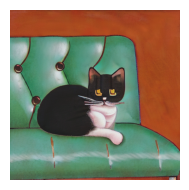

----- Image 2 -----
Fitness: 0.2128119 Descriptors: [-33.867165  26.720253]


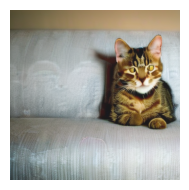

----- Image 3 -----
Fitness: 0.20577507 Descriptors: [-23.32785    -0.7805071]


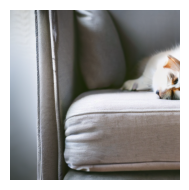

----- Image 4 -----
Fitness: 0.2012283 Descriptors: [-55.847107  28.477213]


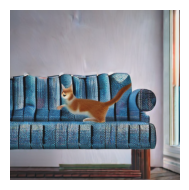

----- Image 5 -----
Fitness: 0.19872499 Descriptors: [-40.603016 -18.005116]


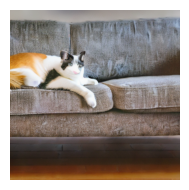

----- Image 6 -----
Fitness: 0.19782157 Descriptors: [-8.321285  -3.1756983]


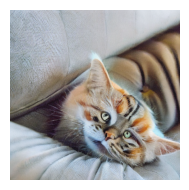

----- Image 7 -----
Fitness: 0.18409005 Descriptors: [-21.83276   27.212034]


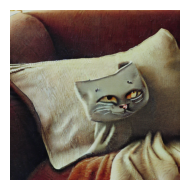

----- Image 8 -----
Fitness: 0.17866465 Descriptors: [-27.440842  18.93406 ]


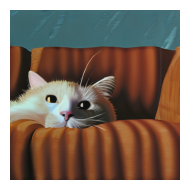

----- Image 9 -----
Fitness: 0.20574003 Descriptors: [-29.80347   35.152428]


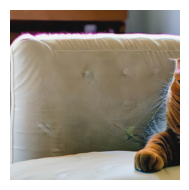

----- Image 10 -----
Fitness: 0.19041073 Descriptors: [ 7.6861925 42.619064 ]


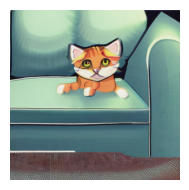

----- Image 11 -----
Fitness: 0.20751011 Descriptors: [-24.435408  17.169338]


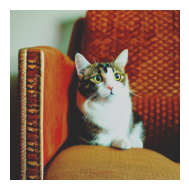

----- Image 12 -----
Fitness: 0.20718889 Descriptors: [-47.835323  12.62962 ]


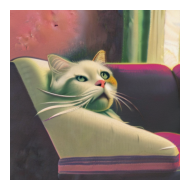

----- Image 13 -----
Fitness: 0.2306683 Descriptors: [13.100942 29.34763 ]


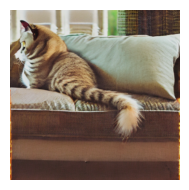

----- Image 14 -----
Fitness: 0.20018117 Descriptors: [-45.34047  -23.577944]


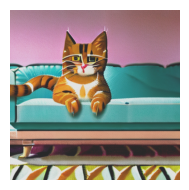

----- Image 15 -----
Fitness: 0.2194833 Descriptors: [-47.270424 -12.258977]


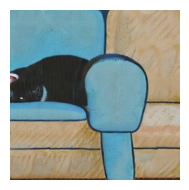

----- Image 16 -----
Fitness: 0.20642792 Descriptors: [ -6.208422 -15.048548]


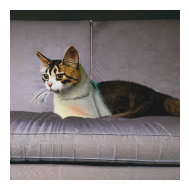

----- Image 17 -----
Fitness: 0.20304169 Descriptors: [-6.7535577 21.844528 ]


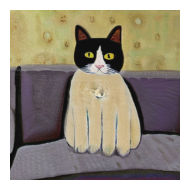

----- Image 18 -----
Fitness: 0.21645537 Descriptors: [9.7052555 9.912308 ]


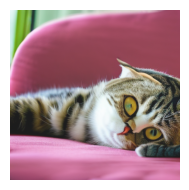

----- Image 19 -----
Fitness: 0.19045252 Descriptors: [-10.058275   11.4534855]


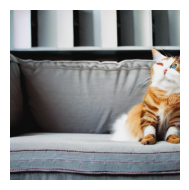

----- Image 20 -----
Fitness: 0.21739577 Descriptors: [-39.150642  70.91829 ]


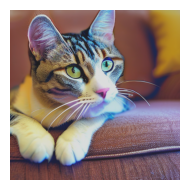

In [48]:
prompt = "a cat on a sofa"
batch_size = 20

def make_latents(seed, batch, H=64, W=64, device="cuda"):
    g = torch.Generator(device=device).manual_seed(seed)
    return torch.randn((1, 4, H, W), generator=g, device=device, dtype=torch.float32)

seeds = [1232, 1235, 1236, 1237, 80, 81, 82, 83, 84, 85, 10, 11, 13, 17, 20, 21, 22, 23, 24, 27]  # Example: make N different seeds in one batch
latents = torch.stack([make_latents(s, 1).squeeze(0) for s in seeds], dim=0)  # (N,4,64,64)
prompt_embedding = get_text_embeddings(
    prompt=prompt,
    batch_size=batch_size,  # type: ignore
    tokenizer=tokenizer,
    text_encoder=text_encoder,
    with_grad=False,  # No gradients needed for initial image generation
)
prompt_embeddings = expand_prompt_embedding(init_prompt_embedding, batch_size)

imgs = generate_images_from_latents(
    latents=latents,                # (N,4,64,64)
    prompt_embedding=prompt_embedding,          # (2N,77,768) if you kept your CFG concatenation
    num_inference_steps=num_inference_steps,
    guidance_scale=guidance_scale,
    scheduler=scheduler,
    unet=unet,
    vae=vae
)
   
fitnesses, descriptors = score_batch(
    latents,
    toggle_prompt_embedding_shape(prompt_embeddings),
    prompt,
    key,
)

for i, img in enumerate(imgs):
    print(f"----- Image {i+1} -----")
    print("Fitness:", fitnesses[i], "Descriptors:", descriptors[i])
    show_image(img)
    

------------ DNS Repertoire Added Images ------------
---- IMAGE 0: fitness 0.21117375791072845, descriptor [-55.847107  28.477213] ----


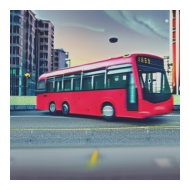

---- IMAGE 1: fitness 0.2087748795747757, descriptor [ 7.6861925 42.619064 ] ----


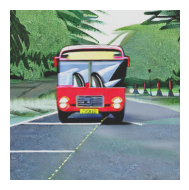

---- IMAGE 2: fitness 0.2405402809381485, descriptor [-24.435408  17.169338] ----


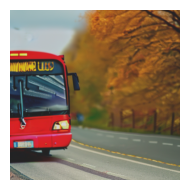

---- IMAGE 3: fitness 0.21810942888259888, descriptor [-47.835323  12.62962 ] ----


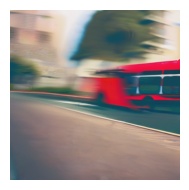

---- IMAGE 4: fitness 0.22685940563678741, descriptor [13.100942 29.34763 ] ----


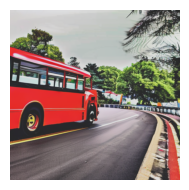

---- IMAGE 5: fitness 0.2164621502161026, descriptor [-45.34047  -23.577944] ----


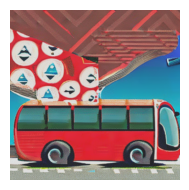

---- IMAGE 6: fitness 0.20243580639362335, descriptor [ -6.208422 -15.048548] ----


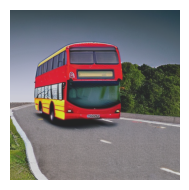

---- IMAGE 7: fitness 0.18386128544807434, descriptor [-39.150642  70.91829 ] ----


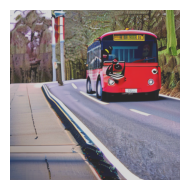

------------ ME Repertoire Added Images ------------
---- IMAGE 0: fitness 0.2405402809381485, descriptor [-24.435408  17.169338] ----


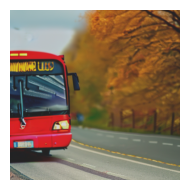

---- IMAGE 1: fitness 0.21810942888259888, descriptor [-47.835323  12.62962 ] ----


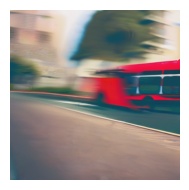

---- IMAGE 2: fitness 0.22685940563678741, descriptor [13.100942 29.34763 ] ----


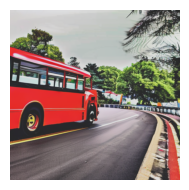

---- IMAGE 3: fitness 0.2164621502161026, descriptor [-45.34047  -23.577944] ----


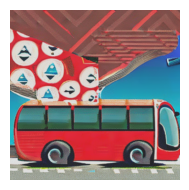

---- IMAGE 4: fitness 0.20243580639362335, descriptor [ -6.208422 -15.048548] ----


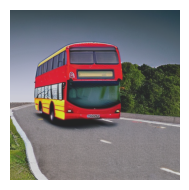

In [47]:
dns_repertoire, me_repertoire, dns_is_added, me_is_added = test_added_to_repertoire(
    latents,
    fitnesses,
    descriptors,
)

added_images = [img for img, keep in zip(imgs, dns_is_added) if keep == 1]
added_descriptors = [descr for descr, keep in zip(descriptors, dns_is_added) if keep == 1]
added_fitnesses = [fit for fit, keep in zip(fitnesses, dns_is_added) if keep == 1]  

print("------------ DNS Repertoire Added Images ------------")
for i, image in enumerate(added_images):
    print(f"---- IMAGE {i}: fitness {added_fitnesses[i]}, descriptor {added_descriptors[i]} ----")
    show_image(image)
    
added_images = [img for img, keep in zip(imgs, me_is_added) if keep == 1]
added_descriptors = [descr for descr, keep in zip(descriptors, me_is_added) if keep == 1]
added_fitnesses = [fit for fit, keep in zip(fitnesses, me_is_added) if keep == 1]

print("------------ ME Repertoire Added Images ------------")
for i, image in enumerate(added_images):
    print(f"---- IMAGE {i}: fitness {added_fitnesses[i]}, descriptor {added_descriptors[i]} ----")
    show_image(image)

In [ ]:
dns_repertoire, me_repertoire, dns_is_added, me_is_added = test_added_to_repertoire(
    genotypes,
    fitnesses,
    descriptors,
)

added_images = [img for img, keep in zip(new_images, dns_is_added) if keep == 1]
added_descriptors = [descr for descr, keep in zip(descriptors, dns_is_added) if keep == 1]
added_fitnesses = [fit for fit, keep in zip(fitnesses, dns_is_added) if keep == 1]  

print("------------ DNS Repertoire Added Images ------------")
for i, image in enumerate(added_images):
    print(f"---- IMAGE {i}: fitness {added_fitnesses[i]}, descriptor {added_descriptors[i]} ----")
    show_image(image)
    
added_images = [img for img, keep in zip(new_images, me_is_added) if keep == 1]
added_descriptors = [descr for descr, keep in zip(descriptors, me_is_added) if keep == 1]
added_fitnesses = [fit for fit, keep in zip(fitnesses, me_is_added) if keep == 1]

print("------------ ME Repertoire Added Images ------------")
for i, image in enumerate(added_images):
    print(f"---- IMAGE {i}: fitness {added_fitnesses[i]}, descriptor {added_descriptors[i]} ----")
    show_image(image)
    

In [ ]:
added_genotypes = [geno for geno, keep in zip(genotypes, dns_is_added) if keep == 1]

new_new_embeds = []
new_new_images = []

def renorm_tokens(E, ref, eps=1e-8):
    """
    Renormalize each token vector in E to match the per-token norms of ref.
    Shapes:
      E, ref: [B, S, D]
    """
    curr = jnp.linalg.norm(E, axis=-1, keepdims=True)
    target = jnp.linalg.norm(ref, axis=-1, keepdims=True) 
    scale = target / jnp.maximum(curr, eps) # Avoid division by zero
    return E * scale

alphas = [0.6, 0.8]
for genotype in added_genotypes:
    for n in [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10]:
        for alpha in alphas:
            print(f"alpha={alpha}, {n+1}th singular value")
            # multiply ONLY the nth singular value on cond
            new_new_embed = svd_perturb(genotype, mode="sigma_scale", select=n, alpha=alpha, batch_select=1)
            new_new_embed = renorm_tokens(new_new_embed, init_prompt_embedding_jnp)
            new_new_embeds.append(new_new_embed)
            img = generate_images_from_latents(
                init_latent,
                new_new_embed,
                num_inference_steps=num_inference_steps,
                guidance_scale=guidance_scale,
                scheduler=scheduler,
                unet=unet,
                vae=vae,
            ).squeeze()
            show_image(img)